# KDD project: what patterns separate attacks from normal traffic, and do they hold for attacks never seen in training?

This notebook follows the course's five KDD steps (**Selection, Preprocessing, Transformation, Data Mining, Interpretation/Evaluation**) with Fayyad, Piatetsky-Shapiro and Smyth's (1996) nine-step process mapped in: step 1 (domain and goals) comes first, steps 5 to 7 are the Data Mining stage, step 8 is Interpretation, and step 9 (using the knowledge) is labelled an **extension** because the course's five steps stop before it.
**Data:** NSL-KDD (Tavallaee, Bagheri, Lu, Ghorbani, "A detailed analysis of the KDD CUP 99 data set", 2009), Kaggle `hassan06/nslkdd`. The Kaggle page lists the license as Unknown, so the original authors are credited.
**Warning:** the traffic is simulated and derives from a 1998 capture. Nothing here claims that the patterns apply to modern networks.
In Colab, add a Kaggle API token as the secret `KAGGLE_API_TOKEN`; locally the files are read from `data/`.

In [1]:
import sys, os, json, subprocess, warnings, random, hashlib, datetime, time
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn==1.9.1", "lightgbm==4.7.0", "pandas==3.1.1", "mlxtend"], check=True)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 170, "display.max_columns", 50, "display.max_rows", 120)
cwd = Path.cwd()
ROOT = Path("/content/kdd_nsl") if IN_COLAB else (cwd.parent if cwd.name == "notebooks" else cwd)
DATA, ART, FIG, DEP = ROOT / "data", ROOT / "artifacts", ROOT / "artifacts" / "figures", ROOT / "deployment"
for p in (DATA, FIG, DEP): p.mkdir(parents=True, exist_ok=True)
import sklearn, lightgbm
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| lightgbm", lightgbm.__version__, "| seed", SEED)
MODULE_SRC = r'''"""Shared code for the NSL-KDD knowledge-discovery project: loading, label grouping, feature preparation,
discretization for association rules, and rule matching. Used by the notebook and by the FastAPI service.
Everything fitted (scalers, categories, bin edges) is learned from training rows only."""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

COLS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent", "hot", "num_failed_logins",
        "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells", "num_access_files",
        "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate",
        "srv_rerror_rate", "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
        "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
        "dst_host_rerror_rate", "dst_host_srv_rerror_rate"]
ALL_COLS = COLS + ["label", "difficulty"]
CAT_COLS = ["protocol_type", "service", "flag"]
BINARY_COLS = ["land", "logged_in", "is_host_login", "is_guest_login"]
RATE_COLS = [c for c in COLS if c.endswith("_rate")]
NUM_COLS = [c for c in COLS if c not in CAT_COLS]
CATEGORIES = ["normal", "DoS", "Probe", "R2L", "U2R"]

# Attack type to category. The widely used convention, from the KDD Cup 99 task description plus the 17 test-only types;
# the data files do not contain categories, so the assignment of the test-only types is a documented convention.
ATTACK_MAP = {
    "normal": "normal",
    **{a: "DoS" for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "mailbomb", "worm"]},
    **{a: "Probe" for a in ["ipsweep", "nmap", "portsweep", "satan", "mscan", "saint"]},
    **{a: "R2L" for a in ["ftp_write", "guess_passwd", "imap", "multihop", "phf", "spy", "warezclient", "warezmaster", "xlock", "xsnoop",
                          "snmpguess", "snmpgetattack", "httptunnel", "named", "sendmail"]},
    **{a: "U2R" for a in ["buffer_overflow", "loadmodule", "perl", "rootkit", "ps", "sqlattack", "xterm"]},
}


def load_nsl(path):
    df = pd.read_csv(path, header=None, names=ALL_COLS)
    return df


def group_labels(label: pd.Series) -> pd.Series:
    return label.map(ATTACK_MAP)


class KDDPrep(BaseEstimator, TransformerMixin):
    """Log-transform skewed numeric columns, standardize numeric columns, one-hot encode protocol_type, service and flag.
    Unseen categories become all zeros. Fit on training rows only."""

    LOG_COLS = ["duration", "src_bytes", "dst_bytes", "hot", "num_compromised", "num_root", "num_file_creations", "count", "srv_count",
                "dst_host_count", "dst_host_srv_count"]

    def __init__(self, drop=("num_outbound_cmds",)):
        self.drop = drop

    def _numeric(self, X):
        num = X[[c for c in NUM_COLS if c not in self.drop]].apply(pd.to_numeric, errors="coerce").astype(float).copy()
        for c in self.LOG_COLS:
            if c in num.columns:
                num[c] = np.log1p(num[c].clip(lower=0))
        return num

    def fit(self, X, y=None):
        num = self._numeric(X)
        self.num_cols_ = list(num.columns)
        self.mean_ = num.mean()
        self.std_ = num.std().replace(0, 1.0)
        self.cats_ = {c: sorted(X[c].astype(str).unique()) for c in CAT_COLS}
        self.feature_names_ = self.num_cols_ + [f"{c}={v}" for c in CAT_COLS for v in self.cats_[c]]
        return self

    def transform(self, X):
        num = (self._numeric(X)[self.num_cols_] - self.mean_) / self.std_
        parts = [num.values]
        for c in CAT_COLS:
            col = X[c].astype(str).values
            parts.append(np.column_stack([(col == v).astype(float) for v in self.cats_[c]]))
        return np.hstack(parts)

    def get_feature_names_out(self, input_features=None):
        return np.array(self.feature_names_, dtype=object)


class RuleDiscretizer(BaseEstimator, TransformerMixin):
    """Turn each connection into a set of items for association rules: categorical values, binary flags, rate columns in
    {zero, low, high} (fixed cut points 0 and 0.5) and counts in {zero, low, mid, high} (training quantile cut points)."""

    COUNT_COLS = [c for c in NUM_COLS if c not in RATE_COLS + BINARY_COLS + ["num_outbound_cmds"]]

    def fit(self, X, y=None):
        self.edges_ = {}
        for c in self.COUNT_COLS:
            v = pd.to_numeric(X[c], errors="coerce")
            nz = v[v > 0]
            self.edges_[c] = np.unique(np.quantile(nz, [1 / 3, 2 / 3])) if len(nz) > 20 else np.array([])
        return self

    def items(self, X) -> pd.DataFrame:
        out = {}
        for c in CAT_COLS:
            for v in sorted(X[c].astype(str).unique()):
                out[f"{c}={v}"] = (X[c].astype(str) == v).values
        for c in BINARY_COLS:
            out[f"{c}=1"] = (pd.to_numeric(X[c]) == 1).values
        for c in RATE_COLS:
            v = pd.to_numeric(X[c]).values
            out[f"{c}=zero"] = v == 0
            out[f"{c}=low"] = (v > 0) & (v <= 0.5)
            out[f"{c}=high"] = v > 0.5
        for c in self.COUNT_COLS:
            v = pd.to_numeric(X[c]).values
            e = self.edges_[c]
            out[f"{c}=zero"] = v == 0
            if len(e) == 2:
                out[f"{c}=low"] = (v > 0) & (v <= e[0])
                out[f"{c}=mid"] = (v > e[0]) & (v <= e[1])
                out[f"{c}=high"] = v > e[1]
            else:
                out[f"{c}=positive"] = v > 0
        return pd.DataFrame(out, index=X.index)

    def transform(self, X):
        return self.items(X)


def match_rules(item_row: pd.Series, rules):
    """Rules (dicts with `antecedent` list, `category`, `confidence`, `lift`, `support`) whose antecedent holds for one item row."""
    held = set(item_row.index[item_row.values])
    return [r for r in rules if set(r["antecedent"]) <= held]


class AnomalyDetector:
    """Detector trained on normal connections only. kind: 'iforest', 'pca_recon' (squared reconstruction error after PCA keeping 95% of
    the variance) or 'mahalanobis' (distance in PCA space). A higher score means more unusual."""

    def __init__(self, kind, seed=42):
        self.kind, self.seed = kind, seed

    def fit(self, df_normal):
        self.prep = KDDPrep().fit(df_normal)
        X = self.prep.transform(df_normal)
        if self.kind == "iforest":
            self.m = IsolationForest(n_estimators=200, random_state=self.seed, n_jobs=4).fit(X)
        else:
            self.pca = PCA(0.95, random_state=self.seed).fit(X)
            self.ev = self.pca.explained_variance_
        return self

    def score(self, df):
        X = self.prep.transform(df)
        if self.kind == "iforest":
            return -self.m.score_samples(X)
        Z = self.pca.transform(X)
        if self.kind == "pca_recon":
            return ((X - self.pca.inverse_transform(Z)) ** 2).sum(axis=1)
        return ((Z ** 2) / self.ev).sum(axis=1)
'''
if MODULE_SRC.strip() and not (DEP / "kdd_features.py").exists():
    (DEP / "kdd_features.py").write_text(MODULE_SRC)
sys.path.insert(0, str(DEP))
import kdd_features as kf

python 3.12.13 | pandas 3.1.1 | sklearn 1.9.1 | lightgbm 4.7.0 | seed 42


# Step 1 (Fayyad): domain and goals, `00_domain_and_goals.md`
**Attack categories** (KDD Cup 99 task description): **DoS** (denial of service: flood a host so it cannot serve, for example `neptune` SYN flood, `smurf`), **Probe** (surveillance and scanning, for example `satan`, `nmap`, `portsweep`), **R2L** (remote to local: an outsider without an account gains access, for example `guess_passwd`, `warezclient`), **U2R** (user to root: a local user gains administrator rights, for example `buffer_overflow`, `rootkit`).
**Feature groups** (41 features per connection): (1) *basic TCP*: duration, protocol, service, flag, bytes each way, `land`, `wrong_fragment`, `urgent`; (2) *content* (inside the payload, from domain knowledge): `hot`, failed logins, `logged_in`, `num_compromised`, `root_shell`, `su_attempted`, `num_root`, file creations, shells, access files, outbound commands, host or guest login; (3) *time-based traffic* over a two-second window: `count`, `srv_count` and the error-rate and same-service-rate features; (4) *host-based traffic* over the last 100 connections to the same host: the `dst_host_*` features.

**Knowledge goals** (fixed before any modeling) and what would count as knowledge in Fayyad's sense (valid, novel, potentially useful, understandable):
| ID | Question | Method | Pass condition (set now) |
|---|---|---|---|
| K1 | Do natural groups of connections line up with the attack categories? | k-means and DBSCAN | k-means NMI against the five categories at least 0.50 on training and at least 0.40 on `KDDTest+` (fitted k-means applied unchanged); DBSCAN is descriptive |
| K2 | Which compact, readable rules characterize each category? | FP-Growth association rules | rules chosen on training only (support within category at least 0.20, at most four items, confidence at least 0.90, ranked by lift, then shorter, then support; top five per category fixed before the test); they must keep confidence at least 0.80 on `KDDTest+` |
| K3 | Can a detector trained on normal traffic only find attacks, including types never seen? | Isolation Forest and a reconstruction-error detector | ROC-AUC (normal vs attack) at least 0.80 on KDDTest+, and recall on **novel** attack types at least 0.50 at the threshold set for 1% false alarms on held-out normal training traffic |
| K4 | How well does supervised classification do per class, on known and novel types? | decision tree, boosted trees | macro-F1 at least 0.55 on `KDDTest+`; attack-vs-normal recall on novel types at least 0.40; all five classes reported with U2R recall, its count and a bootstrap interval |
| K5 | Why do random cross-validation results look so much better than the test results? | validation designs compared with the test | explain the gap with numbers (class mix, novel types) |
**Novel** = understandable and useful: a rule a human can read and check against security knowledge. **Valid** = holds on the held-out test. A pattern that only reflects how the dataset was simulated is marked as an **artifact**, not as knowledge.

**Model-selection rule (fixed now):** primary metric macro-F1 on validation view R; a candidate is eligible if within 0.02 of the best; among the eligible take the highest attack-vs-normal recall on the held-out attack types of view N (simpler model if the bootstrap intervals overlap). Anomaly detectors: ROC-AUC on N, threshold at 1% false alarms on held-out normal records.
**Disclosure.** The project question requires knowing which attack types occur only in test, so attack-type *names and counts* of the test files were inspected while planning (Selection). No model existed, and no modeling choice used those counts. The test is a **characterized test set held out from fitting, tuning, threshold setting and rule selection**, not an unseen one.

# Step 2: Selection, `01_selection.md`
## Which files form the target data

In [2]:
FILES = {"KDDTrain+": DATA / "KDDTrain+.txt", "KDDTest+": DATA / "KDDTest+.txt", "KDDTest-21": DATA / "KDDTest-21.txt", "KDDTrain+_20Percent": DATA / "KDDTrain+_20Percent.txt"}
if not FILES["KDDTrain+"].exists():
    if IN_COLAB:
        from google.colab import userdata
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle", "six"], check=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "hassan06/nslkdd", "-p", str(DATA), "--unzip"], check=True)
raw = {k: kf.load_nsl(v) for k, v in FILES.items()}
tr, te, t21, tr20 = raw["KDDTrain+"], raw["KDDTest+"], raw["KDDTest-21"], raw["KDDTrain+_20Percent"]
key = kf.COLS + ["label"]
def rows_in(a, b): return int(pd.merge(a[key], b[key].drop_duplicates(), on=key, how="inner").shape[0])
sel = pd.DataFrame([
 ("KDDTrain+", len(tr), "used: the training data"),
 ("KDDTest+", len(te), "used: the main test, contains attack types absent from training"),
 ("KDDTest-21", len(t21), f"used: harder subset of KDDTest+ ({rows_in(t21, te)} of its {len(t21)} rows also appear in KDDTest+; difficulty at most {int(t21.difficulty.max())})"),
 ("KDDTrain+_20Percent", len(tr20), f"not used: a subset of KDDTrain+ ({rows_in(tr20, tr)} of {len(tr20)} rows appear in it)")], columns=["file", "records", "role"])
display(sel); sel.to_csv(ART / "selection_files.csv", index=False)
print("records in KDDTest+ that also appear in KDDTrain+ (identical 41 features and label):", rows_in(te, tr), "of", len(te))

,file,records,role
0,KDDTrain+,125973,used: the training data
1,KDDTest+,22544,"used: the main test, contains attack types abs..."
2,KDDTest-21,11850,used: harder subset of KDDTest+ (11850 of its ...
3,KDDTrain+_20Percent,25192,not used: a subset of KDDTrain+ (25192 of 2519...


records in KDDTest+ that also appear in KDDTrain+ (identical 41 features and label): 610 of 22544


## Provenance and how NSL-KDD differs from KDD Cup 99
NSL-KDD was built by Tavallaee et al. (2009) from the KDD Cup 99 data, which itself derives from the 1998 DARPA intrusion-detection evaluation (simulated network traffic captured at MIT Lincoln Laboratory). According to the paper (details not re-verified here): the original training file had about 78% redundant records and the test file about 75%, so classifiers were biased toward frequent records; NSL-KDD **removes duplicate records**, and **samples records from each difficulty level** inversely to their share in the original data, so the number of records is reasonable for whole-set evaluation. The test set is **not from the same distribution as training** and contains attack types absent from it.
The extra last column, `difficulty`, is the number of classifiers (out of 21) that labelled the record correctly. It is derived from how classifiers behaved on the record, so it **must never be a feature**. Targets: the first 41 columns are features; `label` is the attack type; `difficulty` is dropped from modeling.

## Which attack types appear only in test

In [3]:
tr_types, te_types = set(tr.label), set(te.label)
novel_types = sorted(te_types - tr_types); train_only = sorted(tr_types - te_types)
te["category"], tr["category"], t21["category"] = kf.group_labels(te.label), kf.group_labels(tr.label), kf.group_labels(t21.label)
assert tr.category.notna().all() and te.category.notna().all() and t21.category.notna().all(), "unmapped attack type"
te["novel"] = te.label.isin(novel_types); t21["novel"] = t21.label.isin(novel_types)
nt = te[te.novel].groupby(["label", "category"]).size().rename("records_in_KDDTest+").reset_index().sort_values("records_in_KDDTest+", ascending=False)
display(nt); nt.to_csv(ART / "novel_attack_types.csv", index=False)
print(f"{len(novel_types)} attack types occur only in KDDTest+ ({int(te.novel.sum()):,} records, {te.novel.sum() / (te.label != 'normal').sum():.1%} of the attacks in KDDTest+; {int(t21.novel.sum()):,} records in KDDTest-21)")
print("types only in training:", train_only)
mix = pd.DataFrame({"KDDTrain+": tr.category.value_counts(), "KDDTest+": te.category.value_counts(), "KDDTest-21": t21.category.value_counts()}).reindex(kf.CATEGORIES)
mix_pct = (mix / mix.sum()).round(4); display(pd.concat([mix, mix_pct.add_suffix(" share")], axis=1)); mix.to_csv(ART / "class_mix.csv")
shift = pd.DataFrame({"train": tr.label.value_counts(), "test": te.label.value_counts()}).fillna(0).astype(int)
shift = shift[shift.index.isin(tr_types & te_types) & (shift.index != "normal")]
shift["test_per_train"] = (shift.test / shift.train).round(1); display(shift.sort_values("test_per_train", ascending=False).head(8))

,label,category,records_in_KDDTest+
3,mscan,Probe,996
0,apache2,DoS,737
5,processtable,DoS,685
10,snmpguess,R2L,331
7,saint,Probe,319
2,mailbomb,DoS,293
9,snmpgetattack,R2L,178
1,httptunnel,R2L,133
4,named,R2L,17
6,ps,U2R,15


17 attack types occur only in KDDTest+ (3,750 records, 29.2% of the attacks in KDDTest+; 3,740 records in KDDTest-21)
types only in training: ['spy', 'warezclient']


,KDDTrain+,KDDTest+,KDDTest-21,KDDTrain+ share,KDDTest+ share,KDDTest-21 share
category,,,,,,
normal,67343,9711,2152,0.5346,0.4308,0.1816
DoS,45927,7460,4344,0.3646,0.3309,0.3666
Probe,11656,2421,2402,0.0925,0.1074,0.2027
R2L,995,2885,2885,0.0079,0.1280,0.2435
U2R,52,67,67,0.0004,0.0030,0.0057


,train,test,test_per_train
label,,,
warezmaster,20,944,47.2
guess_passwd,53,1231,23.2
multihop,7,18,2.6
rootkit,10,13,1.3
perl,3,2,0.7
buffer_overflow,30,20,0.7
phf,4,2,0.5
back,956,359,0.4


# Step 3: Preprocessing, `02_preprocessing.md`
## Load with the correct names and types, validated against the ARFF documentation

In [4]:
import re
def parse_arff(path):
    spec = {}
    for line in open(path):
        m = re.match(r"@attribute\s+'?([\w\-]+)'?\s+(.*)", line.strip())
        if m: spec[m.group(1)] = m.group(2).strip()
    return spec
spec = parse_arff(DATA / "KDDTrain+.arff")
print("attributes declared in the ARFF file:", len(spec), "| the data files have", len(kf.COLS), "features + label + difficulty")
checks = []
for c in kf.COLS:
    s = spec[c]
    if s.startswith("{"):
        declared = set(re.findall(r"'?([\w\.\-]+)'?", s[1:-1])); observed = set(tr[c].astype(str)) | set(te[c].astype(str)) | set(t21[c].astype(str))
        checks.append((c, "nominal", len(declared), len(observed), bool(observed <= declared), sorted(observed - declared)[:3]))
    else:
        checks.append((c, "numeric", np.nan, np.nan, bool(pd.api.types.is_numeric_dtype(tr[c])), []))
chk = pd.DataFrame(checks, columns=["column", "declared_type", "n_declared", "n_observed", "valid", "undeclared"]); display(chk[chk.declared_type == "nominal"])
print("all columns consistent with the documentation:", bool(chk.valid.all()), "| ARFF class attribute:", spec["class"], "(the ARFF files only say normal or anomaly; attack types come from the .txt files)")
dtypes = tr[kf.COLS].dtypes.astype(str).value_counts().to_dict(); print("dtypes in training:", dtypes)
for name, d in (("KDDTrain+", tr), ("KDDTest+", te), ("KDDTest-21", t21)): assert list(d.columns[:43]) == kf.ALL_COLS and d[kf.COLS].shape[1] == 41, name

attributes declared in the ARFF file: 42 | the data files have 41 features + label + difficulty


,column,declared_type,n_declared,n_observed,valid,undeclared
1,protocol_type,nominal,3.0,3.0,True,[]
2,service,nominal,70.0,70.0,True,[]
3,flag,nominal,11.0,11.0,True,[]
6,land,nominal,2.0,2.0,True,[]
11,logged_in,nominal,2.0,2.0,True,[]
20,is_host_login,nominal,2.0,2.0,True,[]
21,is_guest_login,nominal,2.0,2.0,True,[]


all columns consistent with the documentation: True | ARFF class attribute: {'normal', 'anomaly'} (the ARFF files only say normal or anomaly; attack types come from the .txt files)
dtypes in training: {'int64': 23, 'float64': 15, 'str': 3}


## Missing values, duplicates, invalid values, constant columns, label cleanup

In [5]:
Q = {}
Q["missing_values"] = {k: int(d[kf.COLS + ["label"]].isna().sum().sum()) for k, d in (("train", tr), ("test+", te), ("test-21", t21))}
Q["duplicate_rows"] = {k: int(d[kf.COLS + ["label"]].duplicated().sum()) for k, d in (("train", tr), ("test+", te), ("test-21", t21))}
Q["rates_outside_0_1"] = int(((tr[kf.RATE_COLS] < 0) | (tr[kf.RATE_COLS] > 1)).any(axis=1).sum()) + int(((te[kf.RATE_COLS] < 0) | (te[kf.RATE_COLS] > 1)).any(axis=1).sum())
Q["negative_numeric_values"] = int((tr[kf.NUM_COLS] < 0).any(axis=1).sum()) + int((te[kf.NUM_COLS] < 0).any(axis=1).sum())
Q["binary_columns_not_0_1"] = {c: sorted(set(tr[c]) | set(te[c]) - {0, 1}) for c in kf.BINARY_COLS if not set(tr[c]) | set(te[c]) <= {0, 1}}
Q["label_whitespace_or_case_issues"] = int((tr.label != tr.label.str.strip().str.lower()).sum() + (te.label != te.label.str.strip().str.lower()).sum())
nun = tr[kf.COLS].nunique(); Q["constant_columns_in_train"] = nun[nun <= 1].index.tolist(); Q["near_constant_(>=99.9%_one_value)"] = [c for c in kf.COLS if tr[c].value_counts(normalize=True).iloc[0] >= 0.999 and c not in Q["constant_columns_in_train"]]
print(json.dumps(Q, indent=1))
print("Decision: nothing needs removing (no missing values, no duplicates, no invalid values). `num_outbound_cmds` is constant, so it is dropped from the models.")
print("categories in test that never appear in training:", {c: sorted(set(te[c]) - set(tr[c])) for c in kf.CAT_COLS})

{
 "missing_values": {
  "train": 0,
  "test+": 0,
  "test-21": 0
 },
 "duplicate_rows": {
  "train": 0,
  "test+": 0,
  "test-21": 0
 },
 "rates_outside_0_1": 0,
 "negative_numeric_values": 0,
 "binary_columns_not_0_1": {},
 "label_whitespace_or_case_issues": 0,
 "constant_columns_in_train": [
  "num_outbound_cmds"
 ],
 "near_constant_(>=99.9%_one_value)": [
  "land",
  "urgent",
  "num_failed_logins",
  "su_attempted",
  "num_shells",
  "is_host_login"
 ]
}
Decision: nothing needs removing (no missing values, no duplicates, no invalid values). `num_outbound_cmds` is constant, so it is dropped from the models.


categories in test that never appear in training: {'protocol_type': [], 'service': [], 'flag': []}


## Outlier analysis and decision
Network features are extremely skewed (a few huge transfers, many zeros). Extreme values here are **often the attacks themselves** (flood and bulk-transfer signatures), so deleting them would delete the signal.

In [6]:
sk = tr[["duration", "src_bytes", "dst_bytes", "count", "srv_count", "dst_host_count", "num_root", "hot"]].describe(percentiles=[.5, .99, .999]).T[["50%", "99%", "99.9%", "max"]]
sk["skewness"] = tr[sk.index].skew().round(1); display(sk.round(1))
big = tr.src_bytes > tr.src_bytes.quantile(0.999)
print("share of records above the 99.9th percentile of src_bytes that are attacks:", round((tr.label[big] != "normal").mean(), 3), "| base attack rate:", round((tr.label != "normal").mean(), 3))
print("categories of those extreme src_bytes records:", tr.category[big].value_counts().to_dict())
print("Decision: keep all rows. Apply log1p to the skewed counts and byte fields (Transformation); tree models are unaffected by monotone transforms.")

,50%,99%,99.9%,max,skewness
duration,0.0,9590.6,39964.6,4.290800e+04,11.9
src_bytes,44.0,54540.0,2194619.0,1.379964e+09,190.7
dst_bytes,0.0,25519.0,232327.2,1.309937e+09,290.1
count,14.0,511.0,511.0,5.110000e+02,1.5
srv_count,8.0,492.0,511.0,5.110000e+02,4.7
dst_host_count,255.0,255.0,255.0,2.550000e+02,-0.8
num_root,0.0,0.0,9.0,7.468000e+03,236.9
hot,0.0,3.0,30.0,7.700000e+01,12.6


share of records above the 99.9th percentile of src_bytes that are attacks: 0.764 | base attack rate: 0.465
categories of those extreme src_bytes records: {'R2L': 60, 'normal': 21, 'Probe': 8}
Decision: keep all rows. Apply log1p to the skewed counts and byte fields (Transformation); tree models are unaffected by monotone transforms.


## Group the labels into the attack categories

In [7]:
cat_tab = pd.DataFrame({"KDDTrain+": tr.category.value_counts(), "KDDTest+": te.category.value_counts(), "KDDTest-21": t21.category.value_counts()}).reindex(kf.CATEGORIES)
types = pd.DataFrame([(a, c, int((tr.label == a).sum()), int((te.label == a).sum())) for a, c in kf.ATTACK_MAP.items()], columns=["attack_type", "category", "train", "test+"])
display(types.groupby("category")[["train", "test+"]].agg(["sum"]).reindex(kf.CATEGORIES)); types.to_csv(ART / "attack_type_mapping.csv", index=False)
print("U2R: train", int((tr.category == "U2R").sum()), "| test+", int((te.category == "U2R").sum()), "of which novel types:", int(((te.category == "U2R") & te.novel).sum()))
print("The category assignment of the 17 test-only types is a convention (the data has no category column); it is listed in artifacts/attack_type_mapping.csv.")
json.dump({"Q": Q}, open(ART / "metrics_preprocessing.json", "w"), indent=1, default=str)

,train,test+
,sum,sum
category,,
normal,67343,9711
DoS,45927,7460
Probe,11656,2421
R2L,995,2885
U2R,52,67


U2R: train 52 | test+ 67 of which novel types: 30
The category assignment of the 17 test-only types is a convention (the data has no category column); it is listed in artifacts/attack_type_mapping.csv.


## Validation design (fixed before modeling, built from training data only)
Two validation views are used, because a single random split would repeat the problem the project is about:
- **R (random):** a stratified 80/20 split of KDDTrain+ by attack type. It measures performance on attack types the model has seen, in the training class mix (optimistic).
- **N (pseudo-novel):** hold out **whole attack types** from training: `back`, `teardrop` (DoS), `nmap` (Probe), `warezclient`, `multihop` (R2L), `loadmodule` (U2R), chosen now and not changed. Models are fit without them and scored on them plus a held-out 20% of normal traffic. It simulates "an attack type never seen in training" without touching the test.
Final models are refit on all of KDDTrain+ with the hyperparameters chosen by the model-selection rule above. Inside each view every learned step (scaler, categories, PCA, mutual information, cut points) is refit on that view's fit rows only.

In [8]:
from sklearn.model_selection import train_test_split
NOVEL_VAL_TYPES = ["back", "teardrop", "nmap", "warezclient", "multihop", "loadmodule"]
idx = np.arange(len(tr))
R_fit, R_val = train_test_split(idx, test_size=0.2, stratify=tr.label, random_state=SEED)
is_norm = (tr.label == "normal").values
norm_idx = idx[is_norm]; norm_fit, norm_val = train_test_split(norm_idx, test_size=0.2, random_state=SEED)
held = idx[tr.label.isin(NOVEL_VAL_TYPES).values]
N_fit = np.setdiff1d(idx, np.concatenate([held, norm_val])); N_val = np.concatenate([held, norm_val])
vd = pd.DataFrame({"fit rows": [len(R_fit), len(N_fit)], "validation rows": [len(R_val), len(N_val)]}, index=["R: random stratified", "N: pseudo-novel types held out"]); display(vd)
print("N validation attack records by held-out type:", tr.label.iloc[held].value_counts().to_dict(), "| held-out normal:", len(norm_val))
assert not set(tr.label.iloc[N_fit]) & set(NOVEL_VAL_TYPES)
np.savez(ART / "validation_indices.npz", R_fit=R_fit, R_val=R_val, N_fit=N_fit, N_val=N_val)

,fit rows,validation rows
R: random stratified,100778,25195
N: pseudo-novel types held out,108257,17716


N validation attack records by held-out type: {'nmap': 1493, 'back': 956, 'teardrop': 892, 'warezclient': 890, 'loadmodule': 9, 'multihop': 7} | held-out normal: 13469


# Step 4: Transformation, `03_transformation.md`
## Log transform, scale, encode: one pipeline fit on training rows only
This fit uses all of KDDTrain+ (exploration and the final model). When models are compared on validation views R and N, the same code is refit on each view's fit rows.

In [9]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
prep = kf.KDDPrep().fit(tr[kf.COLS])
Xtr = prep.transform(tr[kf.COLS]); names = np.array(prep.get_feature_names_out())
print("prepared training matrix:", Xtr.shape, "| numeric:", len(prep.num_cols_), "| one-hot:", Xtr.shape[1] - len(prep.num_cols_), "| dropped (constant):", list(prep.drop))
skew_before = tr[["duration", "src_bytes", "dst_bytes", "count", "srv_count", "hot", "num_compromised", "num_root", "num_file_creations"]].skew()
logged = np.log1p(tr[skew_before.index])
sk = pd.DataFrame({"skew_before": skew_before, "skew_after_log1p": logged.skew()}).round(2); display(sk)
# by-hand check that the scaler used training statistics only
manual_mean, manual_std = np.log1p(tr.src_bytes).mean(), np.log1p(tr.src_bytes).std()
print("src_bytes after log1p: pipeline mean/std", round(float(prep.mean_["src_bytes"]), 4), round(float(prep.std_["src_bytes"]), 4), "| by hand", round(float(manual_mean), 4), round(float(manual_std), 4),
      "| equal:", bool(np.isclose(prep.mean_["src_bytes"], manual_mean) and np.isclose(prep.std_["src_bytes"], manual_std)))
Xte_chk = prep.transform(te[kf.COLS])
print("same transform applied to KDDTest+ (not refit):", Xte_chk.shape, "| test mean of the scaled log src_bytes:", round(float(Xte_chk[:, prep.num_cols_.index("src_bytes")].mean()), 3), "(not forced to 0: nothing was fit on test)")
print("unseen categories at transform time become all-zero one-hot rows; none occur here (Preprocessing).")

prepared training matrix: (125973, 121) | numeric: 37 | one-hot: 84 | dropped (constant): ['num_outbound_cmds']


,skew_before,skew_after_log1p
duration,11.88,5.34
src_bytes,190.67,0.31
dst_bytes,290.05,0.49
count,1.51,0.12
srv_count,4.69,0.91
hot,12.59,9.23
num_compromised,250.11,27.51
num_root,236.91,26.43
num_file_creations,55.67,32.43


src_bytes after log1p: pipeline mean/std 3.2297 2.9822 | by hand 3.2297 2.9822 | equal: True
same transform applied to KDDTest+ (not refit): (22544, 121) | test mean of the scaled log src_bytes: 0.143 (not forced to 0: nothing was fit on test)
unseen categories at transform time become all-zero one-hot rows; none occur here (Preprocessing).


## Feature reduction: mutual information and PCA
Mutual information with the attack category (30,000 training records) ranks the features; PCA shows how many components hold 95% of the variance. Both use training data only.

,mutual information
src_bytes,0.715
diff_srv_rate,0.509
dst_bytes,0.461
same_srv_rate,0.459
dst_host_diff_srv_rate,0.454
dst_host_srv_count,0.421
count,0.416
dst_host_serror_rate,0.401
dst_host_same_srv_rate,0.399
serror_rate,0.386


features with MI below 0.001: 29 of 121
PCA: 19 components hold 90% of the variance, 23 hold 95% (of 121)


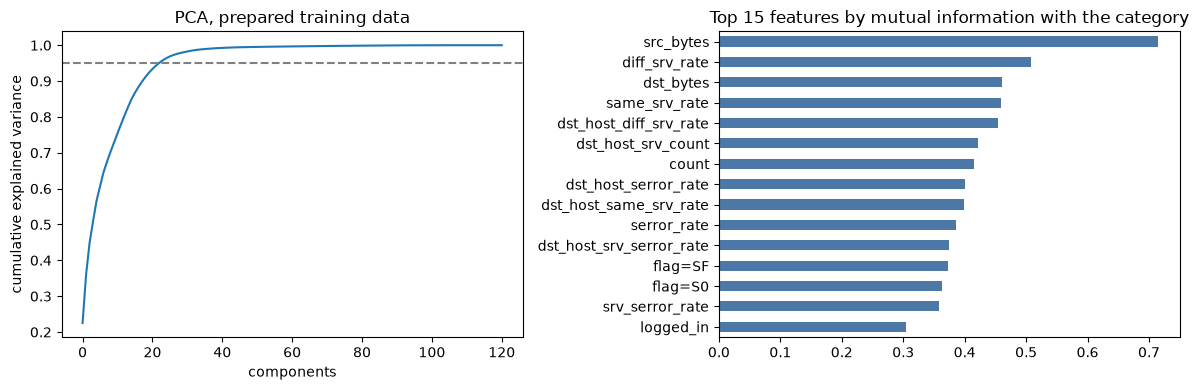

Decisions: supervised models use all 121 prepared features (trees ignore weak ones); clustering uses the first 23 principal components of this fit (the anomaly detectors fit their own preprocessing and PCA on normal records only). The 29 features with MI below 0.001 are mostly rare service one-hots.


In [10]:
samp = np.random.RandomState(SEED).choice(len(tr), 30000, replace=False)
mi = pd.Series(mutual_info_classif(Xtr[samp], tr.category.values[samp], random_state=SEED), index=names).sort_values(ascending=False)
display(mi.head(15).round(3).to_frame("mutual information")); print("features with MI below 0.001:", int((mi < 0.001).sum()), "of", len(mi))
mi.round(4).to_csv(ART / "mutual_information.csv")
pca = PCA(random_state=SEED).fit(Xtr); cum = np.cumsum(pca.explained_variance_ratio_)
K95 = int(np.searchsorted(cum, 0.95) + 1); K90 = int(np.searchsorted(cum, 0.90) + 1)
print(f"PCA: {K90} components hold 90% of the variance, {K95} hold 95% (of {Xtr.shape[1]})")
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); ax[0].plot(cum); ax[0].axhline(0.95, color="grey", ls="--"); ax[0].set_xlabel("components"); ax[0].set_ylabel("cumulative explained variance"); ax[0].set_title("PCA, prepared training data")
mi.head(15)[::-1].plot.barh(ax=ax[1], color="#4C78A8"); ax[1].set_title("Top 15 features by mutual information with the category"); plt.tight_layout(); plt.savefig(FIG / "T_feature_reduction.png", dpi=105); plt.show()
KEEP_MI = mi[mi >= 0.001].index.tolist()
print("Decisions: supervised models use all", Xtr.shape[1], "prepared features (trees ignore weak ones); clustering uses the first", K95, "principal components of this fit (the anomaly detectors fit their own preprocessing and PCA on normal records only). The", int((mi < 0.001).sum()), "features with MI below 0.001 are mostly rare service one-hots.")

## Discretize for association rule mining

In [11]:
disc = kf.RuleDiscretizer().fit(tr[kf.COLS])
items_tr = disc.items(tr[kf.COLS]); print("item matrix:", items_tr.shape, "| items per connection (mean):", round(float(items_tr.sum(axis=1).mean()), 1))
print("example cut points (quantiles of non-zero training values):", {c: disc.edges_[c].round(1).tolist() for c in ["src_bytes", "count", "dst_host_srv_count"]})
prev = items_tr.mean().sort_values(); print("rarest items (share of connections):", prev.head(3).round(5).to_dict(), "| items present in over 99% of connections:", int((prev > 0.99).sum()))
print("example connection (a neptune record):", sorted(items_tr.columns[items_tr.loc[tr.index[tr.label == 'neptune'][0]].values])[:12], "...")

item matrix: (125973, 189) | items per connection (mean): 36.4
example cut points (quantiles of non-zero training values): {'src_bytes': [187.0, 306.0], 'count': [4.0, 107.0], 'dst_host_srv_count': [16.0, 238.0]}
rarest items (share of connections): {'dst_host_count=high': 0.0, 'service=http_2784': 1e-05, 'is_host_login=1': 1e-05} | items present in over 99% of connections: 9
example connection (a neptune record): ['count=high', 'diff_srv_rate=low', 'dst_bytes=zero', 'dst_host_count=mid', 'dst_host_diff_srv_rate=low', 'dst_host_rerror_rate=zero', 'dst_host_same_src_port_rate=zero', 'dst_host_same_srv_rate=low', 'dst_host_serror_rate=high', 'dst_host_srv_count=mid', 'dst_host_srv_diff_host_rate=zero', 'dst_host_srv_rerror_rate=zero'] ...


## Everything fit on train only, in reusable objects

In [12]:
import joblib
joblib.dump({"prep": prep, "disc": disc, "pca95_components": K95}, ART / "preprocessing_objects.joblib", compress=3)
assert np.allclose(joblib.load(ART / "preprocessing_objects.joblib")["prep"].transform(tr[kf.COLS].head(50)), Xtr[:50])
json.dump({"K95": K95, "K90": K90, "n_features": int(Xtr.shape[1]), "n_items": int(items_tr.shape[1])}, open(ART / "metrics_transformation.json", "w"))
print("preprocessing objects saved; reload check passed")

preprocessing objects saved; reload check passed


# Step 5-7: Data Mining, `04_data_mining.md`
**The test files are not touched in this stage.** Every learned step in the validation views is refit on that view's fit rows only.
## Match each knowledge goal to a method
| Goal | Method | Why this method |
|---|---|---|
| K1 natural groups | k-means (k = 5) and DBSCAN on 23 principal components | k-means gives a prediction rule that can be applied to new data (validity check); DBSCAN finds dense regions of any shape and marks noise, which suits unusual traffic |
| K2 readable rules | FP-Growth on the discretized items, mined inside each category | rules with support, confidence and lift are the most understandable knowledge form |
| K3 detect without labels | Isolation Forest, PCA reconstruction error, Mahalanobis distance, fit on normal traffic only | they model "normal" and flag departures, so they can see new attack types |
| K4 classify | baseline logistic regression, interpretable decision tree (depth at most 8), boosted trees (LightGBM) | a spectrum from baseline to strong model; the tree can be read |
Optional LSH for similar connections is **not done**.

In [13]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import normalized_mutual_info_score as nmi, adjusted_rand_score as ari, silhouette_score, roc_auc_score, f1_score, recall_score, precision_score, confusion_matrix
ycat = tr.category.values; y_attack = (tr.label != "normal").values
pca23 = PCA(K95, random_state=SEED).fit(Xtr); Ztr = pca23.transform(Xtr)
rs = np.random.RandomState(SEED)

## K1: clustering (k-means plus DBSCAN)

silhouette by k (15,000 training records): {2: 0.383, 3: 0.461, 4: 0.478, 5: 0.482, 6: 0.481, 8: 0.487, 10: 0.502, 12: 0.511}


k-means k=5 on training: NMI vs 5 categories 0.477 | ARI 0.507 | NMI vs normal/attack 0.432


k = 12 (best silhouette): NMI vs categories 0.471 | ARI 0.468


category,normal,DoS,Probe,R2L,U2R
k-means cluster,,,,,
0,47161,951,34,434,43
1,17149,3757,5916,511,9
2,60,34326,392,0,0
3,73,0,0,1,0
4,2900,6893,5314,49,0


purity of the 5 clusters: 0.838


DBSCAN (eps = 90th percentile of the 10-neighbour distance = 0.98, min_samples 10) on 16047 stratified training records: 46 clusters, noise 7.6% | NMI vs categories 0.588


category,normal,DoS,Probe,R2L,U2R
DBSCAN cluster,,,,,
0,3752,5,28,31,1
-1,717,123,228,103,47
3,139,0,0,0,0
1,77,0,0,0,0
12,66,300,105,1,1
11,39,0,0,0,0
6,28,0,0,0,0
5,23,0,0,0,3
2,22,0,0,0,0


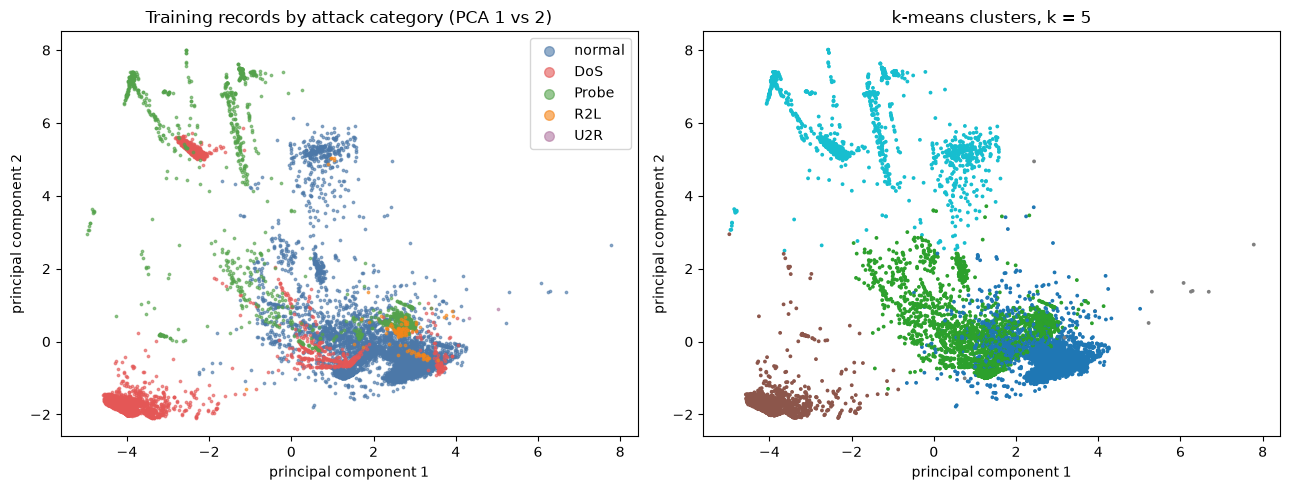

In [14]:
sil_idx = rs.choice(len(Ztr), 15000, replace=False)
sil = {k: round(float(silhouette_score(Ztr[sil_idx], KMeans(k, n_init=3, random_state=SEED).fit_predict(Ztr[sil_idx]))), 3) for k in (2, 3, 4, 5, 6, 8, 10, 12)}
print("silhouette by k (15,000 training records):", sil)
km = KMeans(5, n_init=10, random_state=SEED).fit(Ztr); lab5 = km.labels_
print("k-means k=5 on training: NMI vs 5 categories", round(nmi(ycat, lab5), 3), "| ARI", round(ari(ycat, lab5), 3), "| NMI vs normal/attack", round(nmi(y_attack, lab5), 3))
kbest = max(sil, key=sil.get); kmb = KMeans(kbest, n_init=10, random_state=SEED).fit(Ztr)
print(f"k = {kbest} (best silhouette): NMI vs categories {nmi(ycat, kmb.labels_):.3f} | ARI {ari(ycat, kmb.labels_):.3f}")
comp = pd.crosstab(pd.Series(lab5, name="k-means cluster"), pd.Series(ycat, name="category")).reindex(columns=kf.CATEGORIES); display(comp)
purity = comp.max(axis=1).sum() / comp.values.sum(); print("purity of the 5 clusters:", round(float(purity), 3))
# DBSCAN on a stratified sample (it cannot score new points)
ds = np.concatenate([rs.choice(np.where(ycat == c)[0], min(5000, (ycat == c).sum()), replace=False) for c in kf.CATEGORIES])
from sklearn.neighbors import NearestNeighbors
dk = np.sort(NearestNeighbors(n_neighbors=10).fit(Ztr[ds]).kneighbors(Ztr[ds])[0][:, -1]); eps = float(np.percentile(dk, 90))
db = DBSCAN(eps=eps, min_samples=10).fit(Ztr[ds]); dl = db.labels_
print(f"DBSCAN (eps = 90th percentile of the 10-neighbour distance = {eps:.2f}, min_samples 10) on {len(ds)} stratified training records: {len(set(dl)) - (1 if -1 in dl else 0)} clusters, noise {np.mean(dl == -1):.1%} | NMI vs categories {nmi(ycat[ds], dl):.3f}")
dcomp = pd.crosstab(pd.Series(dl, name="DBSCAN cluster"), pd.Series(ycat[ds], name="category")).reindex(columns=kf.CATEGORIES); display(dcomp.sort_values(kf.CATEGORIES, ascending=False).head(12))
vis = rs.choice(len(Ztr), 15000, replace=False); P2 = Ztr[vis][:, :2]
fig, ax = plt.subplots(1, 2, figsize=(13, 5)); pal = {"normal": "#4C78A8", "DoS": "#E45756", "Probe": "#54A24B", "R2L": "#F58518", "U2R": "#B279A2"}
for c in kf.CATEGORIES: m = ycat[vis] == c; ax[0].scatter(P2[m, 0], P2[m, 1], s=3, c=pal[c], label=c, alpha=.6)
ax[0].legend(markerscale=4); ax[0].set_title("Training records by attack category (PCA 1 vs 2)"); ax[1].scatter(P2[:, 0], P2[:, 1], c=lab5[vis], s=3, cmap="tab10"); ax[1].set_title("k-means clusters, k = 5")
for a in ax: a.set_xlabel("principal component 1"); a.set_ylabel("principal component 2")
plt.tight_layout(); plt.savefig(FIG / "M_clusters.png", dpi=105); plt.show()
CL = {"kmeans_nmi_train": float(nmi(ycat, lab5)), "kmeans_ari_train": float(ari(ycat, lab5)), "purity": float(purity), "silhouette": sil, "dbscan_noise": float(np.mean(dl == -1)), "dbscan_nmi": float(nmi(ycat[ds], dl))}

## K2: association rules (FP-Growth), chosen on training data only
Per category: mine itemsets with support at least 0.20 **inside the category** (at most four items), compute confidence and lift over **all** training records, keep rules with confidence at least 0.90, rank by lift, then shorter antecedent, then support, drop rules that are more specific versions of a better rule, and **fix the top five per category before the test is opened**.

In [15]:
from mlxtend.frequent_patterns import fpgrowth
M_ = items_tr.copy(); prev = M_.mean(); M_ = M_.loc[:, prev <= 0.95]; print("items kept (prevalence at most 95%):", M_.shape[1], "of", items_tr.shape[1])
Mv = M_.values; cols = list(M_.columns); cidx = {c: i for i, c in enumerate(cols)}
RULES, cand_all = [], []
for cat in kf.CATEGORIES:
    in_cat = ycat == cat; p_cat = in_cat.mean()
    fi = fpgrowth(M_[in_cat], min_support=0.20, use_colnames=True, max_len=4)
    rows = []
    for _, r in fi.iterrows():
        a = sorted(r["itemsets"]); mask = np.logical_and.reduce(Mv[:, [cidx[i] for i in a]], axis=1)
        n_a = int(mask.sum()); n_ac = int((mask & in_cat).sum()); conf = n_ac / n_a
        rows.append({"category": cat, "antecedent": a, "length": len(a), "support_in_category": float(r["support"]), "confidence": conf, "lift": conf / p_cat, "records_matched": n_a})
    df_r = pd.DataFrame(rows); n_cand = len(df_r)
    good = df_r[df_r.confidence >= 0.90].sort_values(["lift", "length", "support_in_category"], ascending=[False, True, False]).reset_index(drop=True)
    kept = []
    for _, r in good.iterrows():
        if any(set(k["antecedent"]) < set(r["antecedent"]) and k["confidence"] >= r["confidence"] - 0.005 for k in kept): continue
        kept.append(r.to_dict())
        if len(kept) == 5: break
    RULES += kept; cand_all.append((cat, n_cand, len(good)))
    print(f"{cat}: {n_cand} frequent itemsets (support >= 0.20 in category), {len(good)} with training confidence >= 0.90, {len(kept)} kept")
# Supplementary, exploratory and NOT the pre-registered K2 criterion: R2L at support 0.05 inside the category (still training data only, fixed before the test)
SUPP = []
in_cat = ycat == "R2L"; p_cat = in_cat.mean(); fi = fpgrowth(M_[in_cat], min_support=0.05, use_colnames=True, max_len=3); rows = []
for _, r in fi.iterrows():
    a_ = sorted(r["itemsets"]); mask = np.logical_and.reduce(Mv[:, [cidx[i] for i in a_]], axis=1); n_a = int(mask.sum()); n_ac = int((mask & in_cat).sum())
    rows.append({"category": "R2L", "antecedent": a_, "length": len(a_), "support_in_category": float(r["support"]), "confidence": n_ac / n_a, "lift": n_ac / n_a / p_cat, "records_matched": n_a})
g = pd.DataFrame(rows); g = g[g.confidence >= 0.90].sort_values(["lift", "length", "support_in_category"], ascending=[False, True, False])
for _, r in g.iterrows():
    if any(set(k["antecedent"]) < set(r["antecedent"]) and k["confidence"] >= r["confidence"] - 0.005 for k in SUPP): continue
    SUPP.append(r.to_dict())
    if len(SUPP) == 5: break
print("R2L supplementary (support >= 0.05, at most 3 items):", len(g), "rules with confidence >= 0.90,", len(SUPP), "kept")
rules_df = pd.DataFrame(RULES); rules_df["antecedent_text"] = rules_df.antecedent.map(lambda a: " AND ".join(a))
display(rules_df[["category", "antecedent_text", "support_in_category", "confidence", "lift", "records_matched"]].round(3))
json.dump([{**{k: v for k, v in r.items() if k != "antecedent_text"}} for r in rules_df.to_dict("records")], open(ART / "rules_fixed.json", "w"), indent=1)
supp_df = pd.DataFrame(SUPP)
if len(supp_df): supp_df["antecedent_text"] = supp_df.antecedent.map(lambda a: " AND ".join(a)); display(supp_df[["category", "antecedent_text", "support_in_category", "confidence", "lift", "records_matched"]].round(3))
json.dump(SUPP, open(ART / "rules_supplementary.json", "w"), indent=1)
print("rules fixed and saved (artifacts/rules_fixed.json) before the test is opened")

items kept (prevalence at most 95%): 178 of 189


normal: 23532 frequent itemsets (support >= 0.20 in category), 15325 with training confidence >= 0.90, 5 kept


DoS: 18666 frequent itemsets (support >= 0.20 in category), 15628 with training confidence >= 0.90, 5 kept


Probe: 22598 frequent itemsets (support >= 0.20 in category), 4242 with training confidence >= 0.90, 5 kept


R2L: 32528 frequent itemsets (support >= 0.20 in category), 0 with training confidence >= 0.90, 0 kept


U2R: 35182 frequent itemsets (support >= 0.20 in category), 452 with training confidence >= 0.90, 5 kept


R2L supplementary (support >= 0.05, at most 3 items): 206 rules with confidence >= 0.90, 5 kept


,category,antecedent_text,support_in_category,confidence,lift,records_matched
0,normal,service=http AND src_bytes=mid,0.364,1.000,1.871,24539
1,normal,dst_host_srv_count=high AND src_bytes=mid,0.341,1.000,1.871,22961
2,normal,count=mid AND src_bytes=mid,0.231,1.000,1.871,15555
3,normal,dst_host_diff_srv_rate=zero AND dst_host_srv_d...,0.367,1.000,1.871,24711
4,normal,dst_host_same_srv_rate=high AND dst_host_srv_d...,0.367,1.000,1.871,24711
5,DoS,dst_host_same_srv_rate=low AND dst_host_serror...,0.704,1.000,2.743,32330
6,DoS,diff_srv_rate=low AND dst_host_same_src_port_r...,0.673,1.000,2.743,30904
7,DoS,diff_srv_rate=low AND dst_host_same_src_port_r...,0.673,1.000,2.743,30902
8,DoS,diff_srv_rate=low AND dst_host_same_src_port_r...,0.672,1.000,2.743,30864
9,DoS,count=high AND flag=S0 AND rerror_rate=zero,0.577,1.000,2.743,26479


,category,antecedent_text,support_in_category,confidence,lift,records_matched
0,R2L,duration=low AND is_guest_login=1,0.194,1.0,126.606,193
1,R2L,duration=low AND hot=high AND service=ftp,0.193,1.0,126.606,192
2,R2L,dst_bytes=high AND duration=low AND service=ftp,0.193,1.0,126.606,192
3,R2L,dst_host_diff_srv_rate=low AND duration=low AN...,0.193,1.0,126.606,192
4,R2L,duration=low AND service=ftp AND src_bytes=high,0.193,1.0,126.606,192


rules fixed and saved (artifacts/rules_fixed.json) before the test is opened


## K3: anomaly detection trained on normal traffic only
Each detector learns **normal only**. View N: fit on normal records of the N fit partition; score the held-out attack types plus held-out normal records; the alarm threshold is the 99th percentile of the scores of held-out normal records (1% false alarms).

In [16]:
AnomalyDetector = kf.AnomalyDetector
def eval_detector(kind):
    d = AnomalyDetector(kind).fit(tr.iloc[norm_fit]); s_val = d.score(tr.iloc[N_val]); is_att = (tr.label.iloc[N_val] != "normal").values
    thr = np.percentile(d.score(tr.iloc[norm_val]), 99); alarm = s_val > thr
    per_type = {t: float(alarm[(tr.label.iloc[N_val] == t).values].mean()) for t in NOVEL_VAL_TYPES}
    return d, {"auc": roc_auc_score(is_att, s_val), "recall_at_1pct_FPR": float(alarm[is_att].mean()), "false_alarm_rate": float(alarm[~is_att].mean()), "threshold": float(thr), **{f"recall_{t}": v for t, v in per_type.items()}}
AN, anrow = {}, {}
for kind in ("iforest", "pca_recon", "mahalanobis"): AN[kind], anrow[kind] = eval_detector(kind)
an_tab = pd.DataFrame(anrow).T; display(an_tab.round(3)); an_tab.round(4).to_csv(ART / "anomaly_validation_N.csv")
BEST_AN = an_tab.auc.idxmax(); print("anomaly detector chosen by ROC-AUC on N:", BEST_AN)

,auc,recall_at_1pct_FPR,false_alarm_rate,threshold,recall_back,recall_teardrop,recall_nmap,recall_warezclient,recall_multihop,recall_loadmodule
iforest,0.858,0.093,0.01,0.554,0.005,0.104,0.194,0.004,0.286,0.111
pca_recon,0.921,0.059,0.01,20.507,0.106,0.139,0.002,0.018,0.429,0.333
mahalanobis,0.826,0.064,0.01,212.655,0.000,0.000,0.177,0.002,0.286,0.444


anomaly detector chosen by ROC-AUC on N: pca_recon


## K4: supervised classification, compared on both validation views
The preprocessing is refit on each view's fit rows. Selection rule: macro-F1 on R, eligible within 0.02 of the best, then attack-vs-normal recall on the held-out types of N, simpler model if the bootstrap intervals overlap.

In [17]:
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
CATS = kf.CATEGORIES
def fit_pred(make, fit_idx, val_idx):
    pr = kf.KDDPrep().fit(tr.iloc[fit_idx]); m = make().fit(pr.transform(tr.iloc[fit_idx]), ycat[fit_idx]); return m.predict(pr.transform(tr.iloc[val_idx]))
def boot_ci(x, B=400, seed=SEED):
    r = np.random.RandomState(seed); m = np.array([x[r.randint(0, len(x), len(x))].mean() for _ in range(B)]); return float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))
CANDS = {"Logistic regression (baseline)": ("baseline", 0, lambda: LogisticRegression(max_iter=300, C=1.0))}
for d in (4, 6, 8):
    for cw in (None, "balanced"): CANDS[f"Tree depth {d}, class_weight={cw}"] = ("tree", d, (lambda d=d, cw=cw: DecisionTreeClassifier(max_depth=d, min_samples_leaf=5, class_weight=cw, random_state=SEED)))
for nl in (15, 31):
    for cw in (None, "balanced"): CANDS[f"LightGBM leaves {nl}, class_weight={cw}"] = ("boosted", nl, (lambda nl=nl, cw=cw: lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=nl, class_weight=cw, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, n_jobs=4, verbose=-1)))
rows = []; t0 = time.time()
for name, (fam, cx, make) in CANDS.items():
    pR = fit_pred(make, R_fit, R_val); yR = ycat[R_val]
    pN = fit_pred(make, N_fit, N_val); yN_att = (tr.label.iloc[N_val] != "normal").values; predN_att = pN != "normal"; held_mask = yN_att
    rec = predN_att[held_mask]; lo, hi = boot_ci(rec.astype(float))
    rows.append({"model": name, "family": fam, "R macro-F1": f1_score(yR, pR, average="macro"), "R accuracy": float((yR == pR).mean()), "R U2R recall": recall_score(yR, pR, labels=["U2R"], average=None)[0],
                 "N held-out attack recall": float(rec.mean()), "N CI low": lo, "N CI high": hi, "N false alarm rate": float(predN_att[~yN_att].mean())})
cmp = pd.DataFrame(rows).set_index("model"); display(cmp.round(3)); cmp.round(4).to_csv(ART / "classification_validation.csv"); print("seconds:", round(time.time() - t0))

,family,R macro-F1,R accuracy,R U2R recall,N held-out attack recall,N CI low,N CI high,N false alarm rate
model,,,,,,,,
Logistic regression (baseline),baseline,0.839,0.994,0.3,0.506,0.493,0.519,0.003
"Tree depth 4, class_weight=None",tree,0.650,0.979,0.0,0.295,0.282,0.308,0.007
"Tree depth 4, class_weight=balanced",tree,0.556,0.776,0.9,0.421,0.405,0.437,0.171
"Tree depth 6, class_weight=None",tree,0.866,0.990,0.5,0.293,0.281,0.307,0.002
"Tree depth 6, class_weight=balanced",tree,0.620,0.910,1.0,0.437,0.422,0.452,0.055
"Tree depth 8, class_weight=None",tree,0.873,0.995,0.6,0.295,0.282,0.308,0.001
"Tree depth 8, class_weight=balanced",tree,0.716,0.963,0.7,0.433,0.417,0.446,0.025
"LightGBM leaves 15, class_weight=None",boosted,0.898,0.999,0.5,0.391,0.377,0.405,0.000
"LightGBM leaves 15, class_weight=balanced",boosted,0.969,0.999,0.9,0.432,0.418,0.446,0.000


seconds: 78


In [18]:
def choose(fam):
    """Pre-registered rule: eligible = R macro-F1 within 0.02 of the best; take the highest N recall; if other eligible candidates have a
    95% interval overlapping the best one's, the SIMPLEST of them wins (fewest tree levels or leaves; ties: higher R macro-F1)."""
    c = cmp[cmp.family == fam].copy(); c["complexity"] = [CANDS[n][1] for n in c.index]
    elig = c[c["R macro-F1"] >= c["R macro-F1"].max() - 0.02]; best = elig["N held-out attack recall"].idxmax()
    overlap = elig[elig["N CI high"] >= elig.loc[best, "N CI low"]]; overlap = overlap[overlap["N CI low"] <= elig.loc[best, "N CI high"]]
    pick = overlap.sort_values(["complexity", "R macro-F1"], ascending=[True, False]).index[0]
    return pick, best, list(elig.index), list(overlap.index)
CHOSEN = {}
for fam in ("tree", "boosted"):
    pick, best, elig, overlap = choose(fam); CHOSEN[fam] = pick
    print(f"{fam}: eligible {elig} | highest N recall: {best} | overlapping the best: {overlap} -> chosen (simplest of those): {pick}")
print("chosen:", CHOSEN)

tree: eligible ['Tree depth 6, class_weight=None', 'Tree depth 8, class_weight=None'] | highest N recall: Tree depth 8, class_weight=None | overlapping the best: ['Tree depth 6, class_weight=None', 'Tree depth 8, class_weight=None'] -> chosen (simplest of those): Tree depth 6, class_weight=None
boosted: eligible ['LightGBM leaves 15, class_weight=balanced', 'LightGBM leaves 31, class_weight=balanced'] | highest N recall: LightGBM leaves 15, class_weight=balanced | overlapping the best: ['LightGBM leaves 15, class_weight=balanced'] -> chosen (simplest of those): LightGBM leaves 15, class_weight=balanced
chosen: {'tree': 'Tree depth 6, class_weight=None', 'boosted': 'LightGBM leaves 15, class_weight=balanced'}


## Freeze the final models on all of KDDTrain+ (before the test is opened)

In [19]:
prep_full = kf.KDDPrep().fit(tr[kf.COLS]); Xall = prep_full.transform(tr[kf.COLS])
FINAL = {"baseline": CANDS["Logistic regression (baseline)"][2]().fit(Xall, ycat),
         "tree": CANDS[CHOSEN["tree"]][2]().fit(Xall, ycat), "boosted": CANDS[CHOSEN["boosted"]][2]().fit(Xall, ycat)}
an_final = AnomalyDetector(BEST_AN).fit(tr.iloc[norm_fit]); an_thr = float(np.percentile(an_final.score(tr.iloc[norm_val]), 99))
km_final = km; disc_final = disc
(ART / "frozen").mkdir(exist_ok=True)
bundle = {"prep": prep_full, "disc": disc, "models": FINAL, "anomaly": an_final, "anomaly_threshold": an_thr, "kmeans": km, "pca23": pca23, "rules": RULES, "rules_supplementary": SUPP}
joblib.dump(bundle, ART / "frozen" / "kdd_bundle.joblib", compress=3)
frozen = {"frozen_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"), "test_opened": False, "chosen": CHOSEN, "anomaly_detector": BEST_AN, "anomaly_threshold": an_thr,
          "bundle_sha256": hashlib.sha256((ART / "frozen" / "kdd_bundle.joblib").read_bytes()).hexdigest(), "novel_val_types": NOVEL_VAL_TYPES, "seed": SEED,
          "n_rules": len(RULES), "k1_train": CL}
json.dump(frozen, open(ART / "frozen_policy.json", "w"), indent=1)
print({k: frozen[k] for k in ("frozen_at_utc", "test_opened", "chosen", "anomaly_detector", "anomaly_threshold")})

{'frozen_at_utc': '2026-11-09T21:58:31+00:00', 'test_opened': False, 'chosen': {'tree': 'Tree depth 6, class_weight=None', 'boosted': 'LightGBM leaves 15, class_weight=balanced'}, 'anomaly_detector': 'pca_recon', 'anomaly_threshold': 20.506647098113792}


# Step 8: Interpretation / Evaluation, `05_interpretation.md`
## 5.0 Open the test files (once)
The frozen bundle (preprocessing, three classifiers, anomaly detector and its threshold, k-means, the fixed rules) is loaded and its hash checked. Each model scores `KDDTest+` and `KDDTest-21` once. Nothing is changed afterwards.

In [20]:
frozen = json.load(open(ART / "frozen_policy.json"))
assert hashlib.sha256((ART / "frozen" / "kdd_bundle.joblib").read_bytes()).hexdigest() == frozen["bundle_sha256"], "frozen bundle changed"
B = joblib.load(ART / "frozen" / "kdd_bundle.joblib")
TESTS = {"KDDTest+": te, "KDDTest-21": t21}; PRED = {}
for nm, d in TESTS.items():
    X = B["prep"].transform(d[kf.COLS])                       # the only scoring pass per model
    PRED[nm] = {m: B["models"][m].predict(X) for m in ("baseline", "tree", "boosted")}
    PRED[nm]["classes"] = list(B["models"]["boosted"].classes_); PRED[nm]["proba"] = B["models"]["boosted"].predict_proba(X)
    PRED[nm]["anomaly"] = B["anomaly"].score(d); PRED[nm]["km"] = B["kmeans"].predict(B["pca23"].transform(X))
json.dump({"test_opened_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"), "files_scored": list(TESTS), "scoring_passes_per_model": 1, "bundle_sha256": frozen["bundle_sha256"]}, open(ART / "test_access_log.json", "w"))
print({k: len(v) for k, v in TESTS.items()}, "scored")

{'KDDTest+': 22544, 'KDDTest-21': 11850} scored


## 5.1 Per-class evaluation on KDDTest+ and KDDTest-21

accuracy  macro_F1  macro_F1_CI_low  macro_F1_CI_high  recall_normal  recall_DoS  recall_Probe  recall_R2L  recall_U2R
file       model                                                                                                                           
KDDTest+   baseline     0.741     0.519            0.497             0.545          0.923       0.796         0.704       0.028       0.119
           tree         0.738     0.509            0.488             0.532          0.972       0.749         0.607       0.049       0.075
           boosted      0.780     0.595            0.567             0.619          0.971       0.811         0.726       0.118       0.209
KDDTest-21 baseline     0.507     0.412            0.388             0.438          0.656       0.650         0.702       0.028       0.119
           tree         0.504     0.407            0.386             0.430          0.875       0.574         0.604       0.049       0.075
           boosted      0.583     0.505            0.481             0.533          0.870       0.677         0.724       0.118       0.209


boosted on KDDTest+ (per class)


,precision,recall,f1,records
normal,0.690,0.971,0.806,9711
DoS,0.962,0.811,0.880,7460
Probe,0.792,0.726,0.757,2421
R2L,0.980,0.118,0.210,2885
U2R,0.700,0.209,0.322,67



tree on KDDTest+ (per class)


,precision,recall,f1,records
normal,0.642,0.972,0.773,9711
DoS,0.939,0.749,0.833,7460
Probe,0.851,0.607,0.708,2421
R2L,0.861,0.049,0.093,2885
U2R,0.714,0.075,0.135,67


U2R recall (boosted, KDDTest+): 0.209 (14 of 67) | 95% CI [0.104 0.306] | of the novel-type U2R: 6 of 30


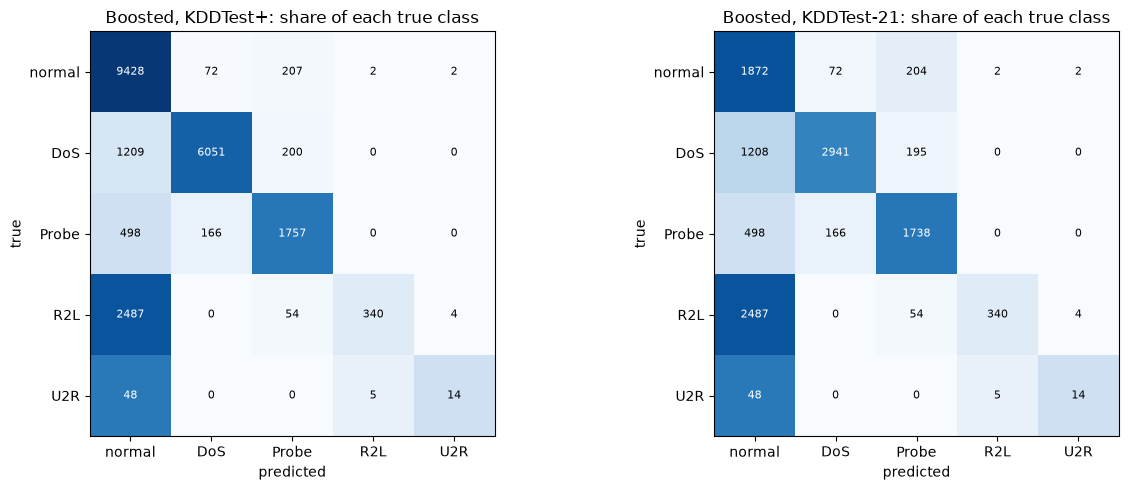

confusion matrix, boosted, KDDTest+ (rows true, columns predicted):


,normal,DoS,Probe,R2L,U2R
normal,9428,72,207,2,2
DoS,1209,6051,200,0,0
Probe,498,166,1757,0,0
R2L,2487,0,54,340,4
U2R,48,0,0,5,14


In [21]:
def per_class(y, p):
    pr, rc, f1, sup = [np.array(v) for v in (precision_score(y, p, labels=kf.CATEGORIES, average=None, zero_division=0), recall_score(y, p, labels=kf.CATEGORIES, average=None, zero_division=0),
                                            f1_score(y, p, labels=kf.CATEGORIES, average=None, zero_division=0), pd.Series(y).value_counts().reindex(kf.CATEGORIES).fillna(0).values)]
    return pd.DataFrame({"precision": pr, "recall": rc, "f1": f1, "records": sup.astype(int)}, index=kf.CATEGORIES)
def ci_boot(y, p, fn, B_=300, seed=SEED):
    r = np.random.RandomState(seed); v = []
    for _ in range(B_): i = r.randint(0, len(y), len(y)); v.append(fn(y[i], p[i]))
    return np.percentile(v, [2.5, 97.5])
summ = []
for nm, d in TESTS.items():
    y = d.category.values
    for m in ("baseline", "tree", "boosted"):
        p = PRED[nm][m]; pc = per_class(y, p); ci = ci_boot(y, p, lambda a, b: f1_score(a, b, average="macro"))
        summ.append({"file": nm, "model": m, "accuracy": float((y == p).mean()), "macro_F1": f1_score(y, p, average="macro"), "macro_F1_CI_low": ci[0], "macro_F1_CI_high": ci[1], **{f"recall_{c}": pc.recall[c] for c in kf.CATEGORIES}})
st = pd.DataFrame(summ).set_index(["file", "model"]); display(st.round(3)); st.round(4).to_csv(ART / "test_summary.csv")
for m in ("boosted", "tree"):
    print(f"\n{m} on KDDTest+ (per class)"); display(per_class(te.category.values, PRED["KDDTest+"][m]).round(3))
u2r = (te.category == "U2R").values; yU = (te.category.values == "U2R").astype(int); pU = (PRED["KDDTest+"]["boosted"] == "U2R").astype(int)
print("U2R recall (boosted, KDDTest+):", round(float(pU[u2r].mean()), 3), f"({int(pU[u2r].sum())} of {int(u2r.sum())}) | 95% CI", np.round(ci_boot(yU[u2r], pU[u2r], lambda a, b: b.mean()), 3), "| of the novel-type U2R:", int(pU[u2r & te.novel.values].sum()), "of", int((u2r & te.novel.values).sum()))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, nm in zip(ax, TESTS):
    cm = confusion_matrix(TESTS[nm].category, PRED[nm]["boosted"], labels=kf.CATEGORIES); cmn = cm / cm.sum(axis=1, keepdims=True)
    a.imshow(cmn, cmap="Blues", vmin=0, vmax=1); a.set_xticks(range(5)); a.set_xticklabels(kf.CATEGORIES); a.set_yticks(range(5)); a.set_yticklabels(kf.CATEGORIES); a.set_title(f"Boosted, {nm}: share of each true class"); a.set_xlabel("predicted"); a.set_ylabel("true")
    for i in range(5):
        for j in range(5): a.text(j, i, f"{cm[i, j]}", ha="center", va="center", color="white" if cmn[i, j] > .5 else "black", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "I_confusion.png", dpi=105); plt.show()
print("confusion matrix, boosted, KDDTest+ (rows true, columns predicted):"); display(pd.DataFrame(confusion_matrix(te.category, PRED["KDDTest+"]["boosted"], labels=kf.CATEGORIES), index=kf.CATEGORIES, columns=kf.CATEGORIES))

## 5.2 Known versus novel attack types; supervised versus anomaly detection

In [22]:
is_att = (te.label != "normal").values; nov = te.novel.values; norm_m = ~is_att
rows = []
for m in ("baseline", "tree", "boosted"):
    p = PRED["KDDTest+"][m]; flag = p != "normal"
    rows.append({"detector": f"supervised {m}", "recall known-type attacks": flag[is_att & ~nov].mean(), "recall novel-type attacks": flag[is_att & nov].mean(), "false alarm rate (normal)": flag[norm_m].mean(),
                 "category correct, known": (p == te.category.values)[is_att & ~nov].mean(), "category correct, novel": (p == te.category.values)[is_att & nov].mean()})
asc = PRED["KDDTest+"]["anomaly"]; thr = frozen["anomaly_threshold"]; alarm = asc > thr
rows.append({"detector": "anomaly (normal-only PCA reconstruction), 1% threshold from validation", "recall known-type attacks": alarm[is_att & ~nov].mean(), "recall novel-type attacks": alarm[is_att & nov].mean(), "false alarm rate (normal)": alarm[norm_m].mean()})
flag_b = PRED["KDDTest+"]["boosted"] != "normal"; union = flag_b | alarm
rows.append({"detector": "union: boosted OR anomaly alarm", "recall known-type attacks": union[is_att & ~nov].mean(), "recall novel-type attacks": union[is_att & nov].mean(), "false alarm rate (normal)": union[norm_m].mean()})
kn = pd.DataFrame(rows).set_index("detector"); display(kn.round(3)); kn.round(4).to_csv(ART / "test_known_vs_novel.csv")
auc_all = roc_auc_score(is_att, asc); auc_known = roc_auc_score(np.r_[np.zeros(norm_m.sum()), np.ones((is_att & ~nov).sum())], np.r_[asc[norm_m], asc[is_att & ~nov]]); auc_nov = roc_auc_score(np.r_[np.zeros(norm_m.sum()), np.ones((is_att & nov).sum())], np.r_[asc[norm_m], asc[is_att & nov]])
print(f"anomaly detector ROC-AUC (attack vs normal) on KDDTest+: all {auc_all:.3f} | known-type attacks only {auc_known:.3f} | novel-type attacks only {auc_nov:.3f}")
# diagnostic only (thresholds taken from the TEST normal scores, so not a deployable setting): why is AUC high while recall at the frozen 1% threshold is low?
def rec_at(f, mask): t = np.percentile(asc[norm_m], 100 * (1 - f)); return float((asc[mask] > t).mean())
diag = pd.DataFrame({f"alarm rate on normal {f:.0%}": {"recall known-type": rec_at(f, is_att & ~nov), "recall novel-type": rec_at(f, is_att & nov)} for f in (0.01, 0.05, 0.10, 0.20)}).T
print("DIAGNOSTIC (post hoc, thresholds from test normals):"); display(diag.round(3)); diag.round(4).to_csv(ART / "test_anomaly_diagnostic.csv")
print("median anomaly score: normal", round(float(np.median(asc[norm_m])), 2), "| known attacks", round(float(np.median(asc[is_att & ~nov])), 2), "| novel attacks", round(float(np.median(asc[is_att & nov])), 2), "| frozen threshold", round(thr, 2))
pt = te[nov].assign(flag=flag_b[nov], alarm=alarm[nov], correct=(PRED["KDDTest+"]["boosted"] == te.category.values)[nov]).groupby(["label", "category"]).agg(records=("flag", "size"), boosted_flags_attack=("flag", "mean"), boosted_correct_category=("correct", "mean"), anomaly_alarm=("alarm", "mean")).sort_values("records", ascending=False)
display(pt.round(3)); pt.round(4).to_csv(ART / "test_novel_types.csv")

,recall known-type attacks,recall novel-type attacks,false alarm rate (normal),"category correct, known","category correct, novel"
detector,,,,,
supervised baseline,0.759,0.311,0.077,0.758,0.227
supervised tree,0.760,0.179,0.028,0.750,0.103
supervised boosted,0.786,0.386,0.029,0.780,0.287
"anomaly (normal-only PCA reconstruction), 1% threshold from validation",0.051,0.100,0.006,NaN,NaN
union: boosted OR anomaly alarm,0.815,0.415,0.034,NaN,NaN


anomaly detector ROC-AUC (attack vs normal) on KDDTest+: all 0.958 | known-type attacks only 0.963 | novel-type attacks only 0.947
DIAGNOSTIC (post hoc, thresholds from test normals):


,recall known-type,recall novel-type
alarm rate on normal 1%,0.271,0.306
alarm rate on normal 5%,0.756,0.671
alarm rate on normal 10%,0.864,0.784
alarm rate on normal 20%,0.999,0.976


median anomaly score: normal 0.24 | known attacks 12.66 | novel attacks 9.3 | frozen threshold 20.51


,,records,boosted_flags_attack,boosted_correct_category,anomaly_alarm
label,category,,,,
mscan,Probe,996,0.501,0.334,0.104
apache2,DoS,737,0.567,0.567,0.228
processtable,DoS,685,0.212,0.000,0.058
snmpguess,R2L,331,0.000,0.000,0.000
saint,Probe,319,0.997,0.997,0.078
mailbomb,DoS,293,0.000,0.000,0.003
snmpgetattack,R2L,178,0.000,0.000,0.000
httptunnel,R2L,133,0.391,0.000,0.105
named,R2L,17,0.118,0.000,0.118


## 5.3 Why random validation looked so much better (K5)

In [23]:
pc_t = per_class(te.category.values, PRED["KDDTest+"]["boosted"]); prior_tr = tr.category.value_counts(normalize=True).reindex(kf.CATEGORIES)
mix_acc = float((prior_tr * pc_t.recall).sum()); known_rows = ~nov
gap = pd.DataFrame([
 ("view R validation (random split of KDDTrain+)", 0.999, 0.969),
 ("KDDTest+ as is", float((te.category.values == PRED['KDDTest+']['boosted']).mean()), f1_score(te.category, PRED['KDDTest+']['boosted'], average="macro")),
 ("KDDTest+, known attack types and normal only", float((te.category.values == PRED['KDDTest+']['boosted'])[known_rows].mean()), f1_score(te.category[known_rows], PRED['KDDTest+']['boosted'][known_rows], average="macro")),
 ("KDDTest+, novel attack types only (accuracy = category correct)", float((te.category.values == PRED['KDDTest+']['boosted'])[nov].mean()), np.nan),
 ("KDDTest+ per-class recall weighted by the TRAINING class mix", mix_acc, np.nan),
 ("KDDTest-21", float((t21.category.values == PRED['KDDTest-21']['boosted']).mean()), f1_score(t21.category, PRED['KDDTest-21']['boosted'], average="macro"))], columns=["view", "accuracy", "macro_F1"]).set_index("view")
display(gap.round(3)); gap.round(4).to_csv(ART / "test_gap_decomposition.csv")
kt = te[te.label.isin(["guess_passwd", "warezmaster"])].assign(ok=lambda d: PRED["KDDTest+"]["boosted"][d.index.values] == d.category.values).groupby("label").agg(test_records=("ok", "size"), recall=("ok", "mean")); kt["train_records"] = [int((tr.label == l).sum()) for l in kt.index]; display(kt.round(3))
print("share of KDDTest+ that is R2L:", round(float((te.category == 'R2L').mean()), 3), "vs", round(float((tr.category == 'R2L').mean()), 4), "in training | R2L recall (boosted) on test:", round(float(pc_t.recall["R2L"]), 3))

,accuracy,macro_F1
view,,
view R validation (random split of KDDTrain+),0.999,0.969
KDDTest+ as is,0.780,0.595
"KDDTest+, known attack types and normal only",0.879,0.674
"KDDTest+, novel attack types only (accuracy = category correct)",0.287,NaN
KDDTest+ per-class recall weighted by the TRAINING class mix,0.883,NaN
KDDTest-21,0.583,0.505


,test_records,recall,train_records
label,,,
guess_passwd,1231,0.000,53
warezmaster,944,0.358,20


share of KDDTest+ that is R2L: 0.128 vs 0.0079 in training | R2L recall (boosted) on test: 0.118


## 5.4 The knowledge goals checked on the test (K1 to K4)

In [24]:
kmN = nmi(te.category, PRED["KDDTest+"]["km"]); kmN21 = nmi(t21.category, PRED["KDDTest-21"]["km"]); kmA = ari(te.category, PRED["KDDTest+"]["km"])
print(f"K1: k-means fitted on training, applied unchanged: NMI on KDDTest+ {kmN:.3f} (ARI {kmA:.3f}), on KDDTest-21 {kmN21:.3f}; on training {frozen['k1_train']['kmeans_nmi_train']:.3f}")
Mt = {nm: B["disc"].items(d[kf.COLS]) for nm, d in TESTS.items()}; rrows = []
for grp, rr in (("fixed (pre-registered)", B["rules"]), ("supplementary (exploratory)", B["rules_supplementary"])):
    for r in rr:
        row = {"group": grp, "category": r["category"], "rule": " AND ".join(r["antecedent"]), "train_conf": r["confidence"], "train_lift": r["lift"]}
        for nm, d in TESTS.items():
            m_ = np.logical_and.reduce(Mt[nm][list(r["antecedent"])].values, axis=1); n_ = int(m_.sum()); row[f"{nm} matched"] = n_
            row[f"{nm} confidence"] = float((d.category.values[m_] == r["category"]).mean()) if n_ >= 1 else np.nan
        rrows.append(row)
rt = pd.DataFrame(rrows); pd.set_option("display.max_colwidth", 90); display(rt.round(3)); rt.round(4).to_csv(ART / "test_rules.csv", index=False)
best_rule = rt[rt.group.str.startswith("fixed")].groupby("category")["KDDTest+ confidence"].max(); print("best fixed-rule confidence on KDDTest+ by category:", best_rule.round(3).to_dict())
rec_n = float(flag_b[is_att & nov].mean()); thr_rec_nov = float(alarm[is_att & nov].mean()); maF = f1_score(te.category, PRED["KDDTest+"]["boosted"], average="macro")
crit = pd.DataFrame([
 ("K1 k-means NMI >= 0.50 on training and >= 0.40 on KDDTest+", f"train {frozen['k1_train']['kmeans_nmi_train']:.3f}; test {kmN:.3f}", bool(frozen['k1_train']['kmeans_nmi_train'] >= 0.5 and kmN >= 0.4)),
 ("K2 each category has a fixed rule (train conf >= 0.90, support >= 0.20) whose test confidence >= 0.80", "; ".join(f"{c}: {('none' if c not in set(r['category'] for r in B['rules']) else round(best_rule.get(c, np.nan), 2))}" for c in kf.CATEGORIES), bool(all(c in set(r['category'] for r in B['rules']) and best_rule.get(c, 0) >= 0.8 for c in kf.CATEGORIES))),
 ("K3 anomaly ROC-AUC >= 0.80 on KDDTest+ and novel-type recall >= 0.50 at the 1% threshold", f"AUC {auc_all:.3f}; novel recall {thr_rec_nov:.3f}", bool(auc_all >= 0.8 and thr_rec_nov >= 0.5)),
 ("K4 macro-F1 (boosted) >= 0.55 on KDDTest+ and novel attack-vs-normal recall >= 0.40", f"macro-F1 {maF:.3f}; novel recall {rec_n:.3f}", bool(maF >= 0.55 and rec_n >= 0.4)),
], columns=["goal and condition", "result", "pass"]); display(crit); crit.to_csv(ART / "test_criteria.csv", index=False)

K1: k-means fitted on training, applied unchanged: NMI on KDDTest+ 0.304 (ARI 0.289), on KDDTest-21 0.223; on training 0.477


,group,category,rule,train_conf,train_lift,KDDTest+ matched,KDDTest+ confidence,KDDTest-21 matched,KDDTest-21 confidence
0,fixed (pre-registered),normal,service=http AND src_bytes=mid,1.000,1.871,4628,1.000,132,1.000
1,fixed (pre-registered),normal,dst_host_srv_count=high AND src_bytes=mid,1.000,1.871,4182,1.000,52,1.000
2,fixed (pre-registered),normal,count=mid AND src_bytes=mid,1.000,1.871,2912,1.000,43,1.000
3,fixed (pre-registered),normal,dst_host_diff_srv_rate=zero AND dst_host_srv_diff_host_rate=low AND service=http,1.000,1.871,4088,1.000,46,1.000
4,fixed (pre-registered),normal,dst_host_same_srv_rate=high AND dst_host_srv_diff_host_rate=low AND service=http,1.000,1.871,4088,1.000,46,1.000
5,fixed (pre-registered),DoS,dst_host_same_srv_rate=low AND dst_host_serror_rate=high AND flag=S0,1.000,2.743,1511,0.891,615,0.733
6,fixed (pre-registered),DoS,diff_srv_rate=low AND dst_host_same_src_port_rate=zero AND flag=S0,1.000,2.743,1395,1.000,423,1.000
7,fixed (pre-registered),DoS,diff_srv_rate=low AND dst_host_same_src_port_rate=zero AND dst_host_srv_serror_rate=high,1.000,2.743,1400,1.000,427,1.000
8,fixed (pre-registered),DoS,diff_srv_rate=low AND dst_host_same_src_port_rate=zero AND srv_serror_rate=high,1.000,2.743,1399,1.000,426,1.000
9,fixed (pre-registered),DoS,count=high AND flag=S0 AND rerror_rate=zero,1.000,2.743,1283,1.000,444,1.000


best fixed-rule confidence on KDDTest+ by category: {'DoS': 1.0, 'Probe': 1.0, 'U2R': 1.0, 'normal': 1.0}


,goal and condition,result,pass
0,K1 k-means NMI >= 0.50 on training and >= 0.40 on KDDTest+,train 0.477; test 0.304,False
1,"K2 each category has a fixed rule (train conf >= 0.90, support >= 0.20) whose test con...",normal: 1.0; DoS: 1.0; Probe: 1.0; R2L: none; U2R: 1.0,False
2,K3 anomaly ROC-AUC >= 0.80 on KDDTest+ and novel-type recall >= 0.50 at the 1% threshold,AUC 0.958; novel recall 0.100,False
3,K4 macro-F1 (boosted) >= 0.55 on KDDTest+ and novel attack-vs-normal recall >= 0.40,macro-F1 0.595; novel recall 0.386,False


## 5.5 Turning patterns into plain-language knowledge

In [25]:
from sklearn.tree import export_text
print("Decision tree (depth 8, frozen), top three levels:"); print(export_text(B["models"]["tree"], max_depth=3, feature_names=list(B["prep"].feature_names_)))
imp = pd.Series(B["models"]["boosted"].booster_.feature_importance("gain"), index=B["prep"].feature_names_).sort_values(ascending=False); display((imp / imp.sum()).head(10).round(3).to_frame("share of total gain (boosted)"))
# which discretized items are most characteristic of each category (lift of the item for the category, on training)
itm = M_.copy(); char = {}
for c in kf.CATEGORIES:
    m_ = ycat == c; sup = itm[m_].mean(); lft = sup / itm.mean(); char[c] = pd.DataFrame({"support_in_category": sup, "lift": lft})[sup >= 0.5].sort_values("lift", ascending=False).head(4).round(2)
for c in ("DoS", "Probe", "R2L", "U2R"): print("\n" + c, "-- items present in at least half of its records, highest lift:"); print(char[c].to_string())
json.dump({"criteria": crit.astype(str).to_dict("records"), "summary": st.round(4).reset_index().to_dict("records")}, open(ART / "metrics_interpretation.json", "w"), indent=1, default=str)

Decision tree (depth 8, frozen), top three levels:
|--- src_bytes <= 0.05
|   |--- count <= -0.80
|   |   |--- dst_host_same_src_port_rate <= 1.15
|   |   |   |--- dst_host_srv_count <= -1.51
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- dst_host_srv_count >  -1.51
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- dst_host_same_src_port_rate >  1.15
|   |   |   |--- service=http <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- service=http >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- count >  -0.80
|   |   |--- dst_host_diff_srv_rate <= 0.33
|   |   |   |--- dst_host_srv_count <= 0.48
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- dst_host_srv_count >  0.48
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- dst_host_diff_srv_rate >  0.33
|   |   |   |--- diff_srv_rate <= 0.07
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- diff_srv_rate >  0.07
|   |   |   |   |

,share of total gain (boosted)
src_bytes,0.169
dst_bytes,0.095
dst_host_srv_count,0.092
flag=S0,0.081
service=telnet,0.077
dst_host_serror_rate,0.064
count,0.056
dst_host_diff_srv_rate,0.047
service=http,0.026
duration,0.024



DoS -- items present in at least half of its records, highest lift:
                               support_in_category  lift
flag=S0                                       0.75  2.70
dst_host_srv_serror_rate=high                 0.74  2.68
serror_rate=high                              0.75  2.68
srv_serror_rate=high                          0.75  2.68

Probe -- items present in at least half of its records, highest lift:
                                  support_in_category  lift
dst_host_same_src_port_rate=high                 0.65  5.24
src_bytes=low                                    0.58  2.84
count=low                                        0.67  1.88
dst_bytes=zero                                   0.98  1.82

R2L -- items present in at least half of its records, highest lift:
                                  support_in_category   lift
service=ftp_data                                 0.61  11.15
dst_host_same_src_port_rate=high                 0.58   4.69
src_bytes=high         

# Step 9: using the knowledge (extension), `06_deployment.md`
SEMMA and the course's five KDD steps stop before this; Fayyad's step 9 is "using the discovered knowledge", labelled an **extension** here.
## FastAPI service, tested through its own HTTP interface

In [26]:
import shutil
shutil.copy(ART / "frozen" / "kdd_bundle.joblib", DEP / "model_bundle.joblib")
bundle_sha = hashlib.sha256((DEP / "model_bundle.joblib").read_bytes()).hexdigest(); assert bundle_sha == frozen["bundle_sha256"]
json.dump({"bundle_sha256": bundle_sha, "anomaly_threshold": B["anomaly_threshold"], "classifier": frozen["chosen"]["boosted"], "anomaly_detector": frozen["anomaly_detector"], "seed": SEED,
           "training_data": "NSL-KDD KDDTrain+ (125,973 connections), a 1998-derived simulation"}, open(DEP / "policy.json", "w"), indent=1)
import importlib, main as api; importlib.reload(api)
from fastapi.testclient import TestClient
pick = {"normal": te.index[te.label == "normal"][0], "neptune (SYN flood)": te.index[te.label == "neptune"][0], "ipsweep": te.index[te.label == "ipsweep"][0],
        "buffer_overflow": te.index[te.label == "buffer_overflow"][0], "mailbomb (novel)": te.index[te.label == "mailbomb"][0]}
with TestClient(api.app) as client:
    h = client.get("/health").json(); print("health:", h)
    rows = []
    for nm, i in pick.items():
        payload = {c: (te.loc[i, c].item() if hasattr(te.loc[i, c], "item") else te.loc[i, c]) for c in kf.COLS}
        r = client.post("/classify", json=payload); assert r.status_code == 200, r.text; j = r.json()
        rows.append({"record": nm, "true label": te.loc[i, "label"], "category": j["category"], "anomaly_score": j["anomaly_score"], "anomaly_alarm": j["anomaly_alarm"], "alert": j["alert"], "matched fixed rules": sum(m["group"] == "fixed" for m in j["matched_rules"])})
        # the service must equal the notebook's own predictions
        assert j["category"] == PRED["KDDTest+"]["boosted"][te.index.get_loc(i)], "service differs from the notebook"
    display(pd.DataFrame(rows))
    ex = client.post("/classify", json={c: (te.loc[pick["neptune (SYN flood)"], c].item() if hasattr(te.loc[pick["neptune (SYN flood)"], c], "item") else te.loc[pick["neptune (SYN flood)"], c]) for c in kf.COLS}).json()
    print("example matched rules for the neptune record:", [m["rule"] for m in ex["matched_rules"]][:2])
    base = {c: (te.loc[pick["normal"], c].item() if hasattr(te.loc[pick["normal"], c], "item") else te.loc[pick["normal"], c]) for c in kf.COLS}
    bad1 = {**base, "serror_rate": 1.7}; bad2 = {**base, "service": "not_a_service"}; bad3 = {k: v for k, v in base.items() if k != "duration"}
    codes = [client.post("/classify", json=b).status_code for b in (bad1, bad2, bad3)]; print("invalid inputs (rate above 1, unknown service, missing field) give HTTP", codes)
    assert codes == [422, 422, 422]
    batch = client.post("/classify_batch", json=[{c: (te.loc[i, c].item() if hasattr(te.loc[i, c], "item") else te.loc[i, c]) for c in kf.COLS} for i in te.index[:50]]); print("batch of 50:", batch.status_code, "| alerts:", sum(x["alert"] for x in batch.json()))
# integrity: a tampered bundle must be refused at start
tmpd = Path(__import__("tempfile").mkdtemp()); [shutil.copy(DEP / f, tmpd / f) for f in ("main.py", "kdd_features.py", "policy.json", "model_bundle.joblib")]
(tmpd / "model_bundle.joblib").write_bytes((tmpd / "model_bundle.joblib").read_bytes() + b"x")
r_ = subprocess.run([sys.executable, "-c", "import main\nfrom fastapi.testclient import TestClient\nwith TestClient(main.app): pass"], cwd=tmpd, capture_output=True, text=True)
print("tampered bundle refused at start:", r_.returncode != 0 and "does not match policy.json" in (r_.stderr + r_.stdout))

health: {'status': 'ok', 'model_hash': '2bee09fa0946284e', 'anomaly_threshold': 20.506647098113792}


,record,true label,category,anomaly_score,anomaly_alarm,alert,matched fixed rules
0,normal,normal,normal,1.773,False,False,0
1,neptune (SYN flood),neptune,DoS,13.728,False,True,0
2,ipsweep,ipsweep,Probe,2.882,False,True,3
3,buffer_overflow,buffer_overflow,normal,10.796,False,False,0
4,mailbomb (novel),mailbomb,normal,1.314,False,False,0


example matched rules for the neptune record: []
invalid inputs (rate above 1, unknown service, missing field) give HTTP [422, 422, 422]


batch of 50: 200 | alerts: 21


tampered bundle refused at start: True


## Monitoring plan, demonstrated by treating `KDDTest+` as the live stream
Checks: feature drift (PSI), alert volume against the training baseline, analyst feedback precision, retraining triggers (`deployment/kdd_monitor.py`).

In [27]:
import kdd_monitor as mon
drift = mon.feature_drift(tr, te, ["src_bytes", "dst_bytes", "count", "srv_count", "dst_host_count", "dst_host_srv_count", "serror_rate", "same_srv_rate", "diff_srv_rate", "logged_in", "duration"])
print("feature PSI, training vs KDDTest+ (top):", drift.head(6).round(3).to_dict())
base_rate = float((B["models"]["boosted"].predict(B["prep"].transform(tr[kf.COLS])) != "normal").mean()); stream_alerts = (PRED["KDDTest+"]["boosted"] != "normal") | (PRED["KDDTest+"]["anomaly"] > B["anomaly_threshold"])
ai = mon.alert_report(stream_alerts, base_rate); print("alert rate in the stream:", round(ai["alert_rate"], 3), "| training baseline:", round(base_rate, 3), "| ratio:", round(ai["ratio_to_baseline"], 2))
prec = float((te.label.values[stream_alerts] != "normal").mean()); print("precision of the alerts in the stream (analyst-confirmed share, here from the test labels):", round(prec, 3))
for m_ in mon.alerts(drift, ai, prec): print(" -", m_)
print("note: the thresholds were set before the stream was scored; a watch message is a prompt to look, not a retrain order.")

feature PSI, training vs KDDTest+ (top): {'serror_rate': 0.197, 'dst_host_srv_count': 0.065, 'count': 0.039, 'same_srv_rate': 0.029, 'srv_count': 0.028, 'diff_srv_rate': 0.026}


alert rate in the stream: 0.412 | training baseline: 0.465 | ratio: 0.89
precision of the alerts in the stream (analyst-confirmed share, here from the test labels): 0.964
 - feature drift serror_rate: PSI 0.20 (> 0.1): WATCH
note: the thresholds were set before the stream was scored; a watch message is a prompt to look, not a retrain order.


## Summary

In [28]:
print("Chosen:", frozen["chosen"], "| anomaly:", frozen["anomaly_detector"])
print("KDDTest+ boosted: accuracy", round(float((te.category.values == PRED['KDDTest+']['boosted']).mean()), 3), "| macro-F1", round(float(maF), 3), "| goal verdicts:", crit["pass"].tolist())

Chosen: {'tree': 'Tree depth 6, class_weight=None', 'boosted': 'LightGBM leaves 15, class_weight=balanced'} | anomaly: pca_recon
KDDTest+ boosted: accuracy 0.78 | macro-F1 0.595 | goal verdicts: [False, False, False, False]
